<a href="https://colab.research.google.com/github/subhamsmmaity/PYPROJECT/blob/main/HPMCONSOLE1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


===== HOSPITAL MANAGEMENT SYSTEM =====
1. Add Patient
2. View Patients
3. Add Doctor
4. Book Appointment
5. Admit Patient / Allocate Room
6. Discharge Patient
7. Generate Bill
8. Statistics and Graph
9. View Appointments
10. Save Records to Excel
11. Exit
Patient added successfully!

===== HOSPITAL MANAGEMENT SYSTEM =====
1. Add Patient
2. View Patients
3. Add Doctor
4. Book Appointment
5. Admit Patient / Allocate Room
6. Discharge Patient
7. Generate Bill
8. Statistics and Graph
9. View Appointments
10. Save Records to Excel
11. Exit

Total Patients: 1
Total Doctors: 0
Total Appointments: 0
Total Bills: 0


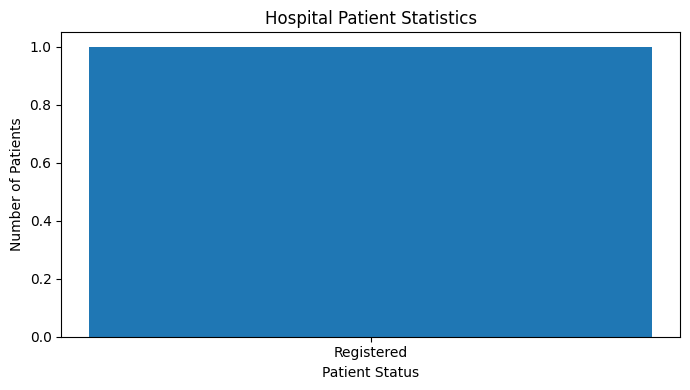


===== HOSPITAL MANAGEMENT SYSTEM =====
1. Add Patient
2. View Patients
3. Add Doctor
4. Book Appointment
5. Admit Patient / Allocate Room
6. Discharge Patient
7. Generate Bill
8. Statistics and Graph
9. View Appointments
10. Save Records to Excel
11. Exit


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date

patients = []
doctors = []
appointments = []
bills = []

rooms = {
    1: {"type": "General", "charge": 500, "status": "Available"},
    2: {"type": "General", "charge": 500, "status": "Available"},
    3: {"type": "Private", "charge": 2000, "status": "Available"},
    4: {"type": "Private", "charge": 2000, "status": "Available"}
}


# 1. Add Patient
def add_patient():
    pid = input("Patient ID: ").strip()

    if any(p["ID"] == pid for p in patients):
        print("Patient ID already exists!")
        return

    name = input("Patient Name: ").strip()

    try:
        age = int(input("Age: "))
        if age < 0 or age > 120:
            print("Enter a valid age.")
            return
    except ValueError:
        print("Age must be a number.")
        return

    disease = input("Disease: ").strip()

    patients.append({
        "ID": pid,
        "Name": name,
        "Age": age,
        "Disease": disease,
        "Status": "Registered",
        "Room": None
    })

    print("Patient added successfully!")


# 2. View Patients
def view_patients():
    if patients:
        print(pd.DataFrame(patients).to_string(index=False))
    else:
        print("No patients found.")


# 3. Add Doctor
def add_doctor():
    did = input("Doctor ID: ").strip()

    if any(d["ID"] == did for d in doctors):
        print("Doctor ID already exists!")
        return

    name = input("Doctor Name: ").strip()
    specialization = input("Specialization: ").strip()

    doctors.append({
        "ID": did,
        "Name": name,
        "Specialization": specialization
    })

    print("Doctor added successfully!")


# 4. Book Appointment
def book_appointment():
    pid = input("Patient ID: ").strip()
    did = input("Doctor ID: ").strip()

    patient = next((p for p in patients if p["ID"] == pid), None)
    doctor = next((d for d in doctors if d["ID"] == did), None)

    if not patient or not doctor:
        print("Patient or doctor not found.")
        return

    appointments.append({
        "Patient": patient["Name"],
        "Doctor": doctor["Name"],
        "Date": date.today().isoformat()
    })

    print("Appointment booked successfully!")


# 5. Admit Patient and Allocate Room
def admit_patient():
    pid = input("Patient ID: ").strip()
    patient = next((p for p in patients if p["ID"] == pid), None)

    if not patient:
        print("Patient not found.")
        return

    if patient["Status"] == "Admitted":
        print("Patient is already admitted.")
        return

    available = [
        room_no for room_no, details in rooms.items()
        if details["status"] == "Available"
    ]

    if not available:
        print("No rooms available.")
        return

    print("Available rooms:", available)

    try:
        room_no = int(input("Choose room number: "))
    except ValueError:
        print("Enter a valid room number.")
        return

    if room_no not in available:
        print("Invalid room selection.")
        return

    rooms[room_no]["status"] = "Occupied"
    patient["Room"] = room_no
    patient["Status"] = "Admitted"

    print("Patient admitted to room", room_no)


# 6. Discharge Patient
def discharge_patient():
    pid = input("Patient ID: ").strip()
    patient = next((p for p in patients if p["ID"] == pid), None)

    if not patient:
        print("Patient not found.")
        return

    if patient["Status"] != "Admitted":
        print("Patient is not admitted.")
        return

    room_no = patient["Room"]
    rooms[room_no]["status"] = "Available"
    patient["Room"] = None
    patient["Status"] = "Discharged"

    print("Patient discharged successfully!")


# 7. Generate Bill
def generate_bill():
    pid = input("Patient ID: ").strip()
    patient = next((p for p in patients if p["ID"] == pid), None)

    if not patient:
        print("Patient not found.")
        return

    try:
        consultation = float(input("Consultation fee: "))
        medicine = float(input("Medicine charges: "))
        if consultation < 0 or medicine < 0:
            print("Charges cannot be negative.")
            return
    except ValueError:
        print("Enter valid amounts.")
        return

    room_charge = 0
    if patient["Room"] is not None:
        room_charge = rooms[patient["Room"]]["charge"]

    total = consultation + medicine + room_charge

    bill = {
        "Patient ID": pid,
        "Patient Name": patient["Name"],
        "Consultation": consultation,
        "Medicine": medicine,
        "Room Charge": room_charge,
        "Total": total
    }
    bills.append(bill)

    print("\n------ HOSPITAL BILL ------")
    print("Patient:", patient["Name"])
    print("Consultation: Rs.", consultation)
    print("Medicine: Rs.", medicine)
    print("Room Charge: Rs.", room_charge)
    print("Total Amount: Rs.", total)
    print("---------------------------")


# 8. Hospital Statistics and Graph
def statistics():
    print("\nTotal Patients:", len(patients))
    print("Total Doctors:", len(doctors))
    print("Total Appointments:", len(appointments))
    print("Total Bills:", len(bills))

    if not patients:
        print("Add patients to display the graph.")
        return

    status_counts = {}
    for patient in patients:
        status = patient["Status"]
        status_counts[status] = status_counts.get(status, 0) + 1

    plt.figure(figsize=(7, 4))
    plt.bar(status_counts.keys(), status_counts.values())
    plt.title("Hospital Patient Statistics")
    plt.xlabel("Patient Status")
    plt.ylabel("Number of Patients")
    plt.tight_layout()
    plt.show()


# 9. View Appointments
def view_appointments():
    if appointments:
        print(pd.DataFrame(appointments).to_string(index=False))
    else:
        print("No appointments found.")


# 10. Save All Records to Excel
def save_records():
    try:
        with pd.ExcelWriter("hospital_records.xlsx") as writer:
            pd.DataFrame(patients).to_excel(
                writer, sheet_name="Patients", index=False
            )
            pd.DataFrame(doctors).to_excel(
                writer, sheet_name="Doctors", index=False
            )
            pd.DataFrame(appointments).to_excel(
                writer, sheet_name="Appointments", index=False
            )
            pd.DataFrame(bills).to_excel(
                writer, sheet_name="Bills", index=False
            )

        print("Records saved to hospital_records.xlsx")
    except Exception as error:
        print("Could not save records:", error)


# Main Menu
def main():
    while True:
        print("\n===== HOSPITAL MANAGEMENT SYSTEM =====")
        print("1. Add Patient")
        print("2. View Patients")
        print("3. Add Doctor")
        print("4. Book Appointment")
        print("5. Admit Patient / Allocate Room")
        print("6. Discharge Patient")
        print("7. Generate Bill")
        print("8. Statistics and Graph")
        print("9. View Appointments")
        print("10. Save Records to Excel")
        print("11. Exit")

        choice = input("Enter your choice: ").strip()

        if choice == "1":
            add_patient()
        elif choice == "2":
            view_patients()
        elif choice == "3":
            add_doctor()
        elif choice == "4":
            book_appointment()
        elif choice == "5":
            admit_patient()
        elif choice == "6":
            discharge_patient()
        elif choice == "7":
            generate_bill()
        elif choice == "8":
            statistics()
        elif choice == "9":
            view_appointments()
        elif choice == "10":
            save_records()
        elif choice == "11":
            print("Thank you for using Hospital Management System!")
            break
        else:
            print("Invalid choice. Try again.")


if __name__ == "__main__":
    main()
